# Random Forest Model

Predict whether a driver finishes on the podium using only pre-race features from `data/processed/features.csv` (built in `02_preprocessing`).

Seasons are split by time, the way the model would be used in practice:

| Split | Seasons | Used for |
|---|---|---|
| Train | 2014–2022 | Fitting the model |
| Validation | 2023–2024 | Choosing hyperparameters and the decision threshold |
| Test | 2025–2026 | Final evaluation, used once |

Accuracy is misleading here (predicting "no podium" every time is about 81% accurate), so models are compared on precision, recall, F1 and PR-AUC (average precision).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, f1_score, precision_recall_curve,
                             precision_score, recall_score)
from sklearn.model_selection import ParameterGrid

PROCESSED = Path("../data/processed")
FIGURES = Path("../reports/figures")
SEED = 42

ACCENT = "#2a78d6"
ORANGE = "#eb6834"
MUTED = "#c3c2b7"
INK = "#0b0b0b"
INK_2 = "#52514e"

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.edgecolor": MUTED,
    "axes.labelcolor": INK_2,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e8e7e3",
    "grid.linewidth": 0.8,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "text.color": INK,
})

df = pd.read_csv(PROCESSED / "features.csv", parse_dates=["date"])

FEATURES = [
    "grid", "quali_position",
    "driver_avg_finish_5", "driver_avg_points_5", "driver_podiums_5", "driver_starts",
    "team_avg_points_5", "team_best_finish_5",
    "driver_season_points", "driver_champ_pos", "team_season_points", "team_champ_pos",
    "circuit_starts", "circuit_avg_finish", "circuit_podiums",
    "teammate_quali_gap",
]

train = df[df.year <= 2022]
val = df[df.year.between(2023, 2024)]
test = df[df.year >= 2025]

for name, part in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name:<10} {part.year.min()}-{part.year.max()}  rows {len(part):>5,}  races {part.raceId.nunique():>3}  "
          f"podium rate {part.podium.mean():.1%}")

Train      2014-2022  rows 1,803  races 182  podium rate 20.6%
Validation 2023-2024  rows   711  races  46  podium rate 19.4%
Test       2025-2026  rows   884  races  44  podium rate 14.9%


## 1. Baseline: "a top-3 start means a podium"

This is the rule from the EDA. The model has to beat it to be worth using.

In [2]:
def scores(y_true, y_pred, y_prob=None):
    out = {
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
    }
    out["pr_auc"] = average_precision_score(y_true, y_prob) if y_prob is not None else np.nan
    return out


baseline = {name: scores(part.podium, (part.grid <= 3).astype(int))
            for name, part in [("validation", val), ("test", test)]}
pd.DataFrame(baseline).T.round(3)

,precision,recall,f1,pr_auc
validation,0.662,0.652,0.657,NaN
test,0.682,0.682,0.682,NaN


## 2. Tune the random forest on the validation seasons

Each setting is trained on 2014–2022 and scored on 2023–2024 by PR-AUC. `class_weight="balanced_subsample"` makes podiums count as much as non-podiums in each tree. Missing values (a first start, a first visit to a circuit) are handled by the forest directly.

In [3]:
param_grid = ParameterGrid({
    "max_depth": [4, 6, 10, None],
    "min_samples_leaf": [1, 5, 10, 20],
    "max_features": ["sqrt", 0.5],
})


def make_forest(**params):
    return RandomForestClassifier(n_estimators=500, class_weight="balanced_subsample",
                                  random_state=SEED, n_jobs=-1, **params)


rows = []
for params in param_grid:
    model = make_forest(**params).fit(train[FEATURES], train.podium)
    prob = model.predict_proba(val[FEATURES])[:, 1]
    rows.append({**params, "val_pr_auc": average_precision_score(val.podium, prob)})

tuning = pd.DataFrame(rows).sort_values("val_pr_auc", ascending=False)
best_params = tuning.iloc[0][["max_depth", "min_samples_leaf", "max_features"]].to_dict()
best_params["max_depth"] = None if pd.isna(best_params["max_depth"]) else int(best_params["max_depth"])
best_params["min_samples_leaf"] = int(best_params["min_samples_leaf"])
print("Best settings:", best_params)
tuning.head(8).round(3)

Best settings: {'max_depth': 4, 'min_samples_leaf': 20, 'max_features': 'sqrt'}


,max_depth,max_features,min_samples_leaf,val_pr_auc
3,4.0,sqrt,20,0.717
6,4.0,0.5,10,0.715
7,4.0,0.5,20,0.713
2,4.0,sqrt,10,0.712
5,4.0,0.5,5,0.712
15,6.0,0.5,20,0.710
1,4.0,sqrt,5,0.710
23,10.0,0.5,20,0.709


### Choose the decision threshold

The forest outputs a probability. Instead of the default 0.5 cut-off, pick the threshold that gives the best F1 on the validation seasons.

In [4]:
model = make_forest(**best_params).fit(train[FEATURES], train.podium)
val_prob = model.predict_proba(val[FEATURES])[:, 1]

precision, recall, thresholds = precision_recall_curve(val.podium, val_prob)
f1 = 2 * precision * recall / np.clip(precision + recall, 1e-9, None)
best = np.argmax(f1[:-1])
THRESHOLD = thresholds[best]
print(f"Threshold {THRESHOLD:.2f}: validation precision {precision[best]:.3f}, recall {recall[best]:.3f}, F1 {f1[best]:.3f}")

pd.DataFrame({
    "baseline": baseline["validation"],
    "random_forest": scores(val.podium, (val_prob >= THRESHOLD).astype(int), val_prob),
}).T.round(3)

Threshold 0.57: validation precision 0.553, recall 0.833, F1 0.665


,precision,recall,f1,pr_auc
baseline,0.662,0.652,0.657,NaN
random_forest,0.553,0.833,0.665,0.717


## 3. Final test on 2025–2026

The model is refit on 2014–2024 (train plus validation) with the chosen settings and threshold, then scored once on the test seasons. A second forest that only sees `grid` and `quali_position` shows how much the form, standings and circuit features add.

In [5]:
fit_data = pd.concat([train, val])
GRID_ONLY = ["grid", "quali_position"]

final = make_forest(**best_params).fit(fit_data[FEATURES], fit_data.podium)
grid_only = make_forest(**best_params).fit(fit_data[GRID_ONLY], fit_data.podium)

test = test.assign(
    prob=final.predict_proba(test[FEATURES])[:, 1],
    prob_grid_only=grid_only.predict_proba(test[GRID_ONLY])[:, 1],
)
test["pred"] = (test.prob >= THRESHOLD).astype(int)

results = pd.DataFrame({
    "baseline (grid top 3)": baseline["test"],
    "forest, grid + quali only": scores(test.podium, (test.prob_grid_only >= THRESHOLD).astype(int), test.prob_grid_only),
    "forest, all features": scores(test.podium, test.pred, test.prob),
}).T
results.round(3)

,precision,recall,f1,pr_auc
baseline (grid top 3),0.682,0.682,0.682,NaN
"forest, grid + quali only",0.611,0.833,0.705,0.714
"forest, all features",0.609,0.886,0.722,0.731


In [6]:
# Separate seasons: 2026 brought new car rules and two new teams
by_season = {}
for year, part in test.groupby("year"):
    by_season[f"{year} baseline"] = scores(part.podium, (part.grid <= 3).astype(int))
    by_season[f"{year} forest"] = scores(part.podium, part.pred, part.prob)
pd.DataFrame(by_season).T.round(3)

,precision,recall,f1,pr_auc
2025 baseline,0.750,0.750,0.750,NaN
2025 forest,0.644,0.903,0.751,0.785
2026 baseline,0.600,0.600,0.600,NaN
2026 forest,0.571,0.867,0.689,0.668


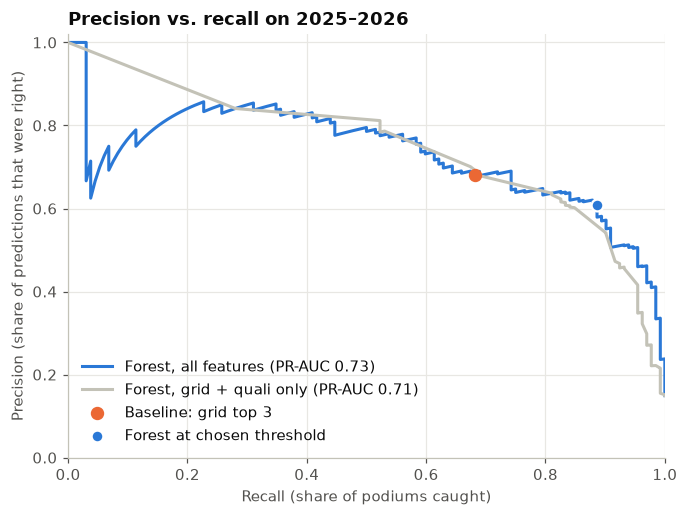

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
for col, label, color in [("prob", "Forest, all features", ACCENT), ("prob_grid_only", "Forest, grid + quali only", MUTED)]:
    p, r, _ = precision_recall_curve(test.podium, test[col])
    ap = average_precision_score(test.podium, test[col])
    ax.plot(r, p, color=color, linewidth=2, label=f"{label} (PR-AUC {ap:.2f})")
b = baseline["test"]
ax.scatter(b["recall"], b["precision"], color=ORANGE, s=60, zorder=3, label="Baseline: grid top 3")
ax.scatter(results.loc["forest, all features", "recall"], results.loc["forest, all features", "precision"],
           color=ACCENT, s=60, zorder=3, edgecolor="white", linewidth=1.5, label="Forest at chosen threshold")
ax.set_xlabel("Recall (share of podiums caught)")
ax.set_ylabel("Precision (share of predictions that were right)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(frameon=False, loc="lower left")
ax.set_title("Precision vs. recall on 2025–2026")
fig.savefig(FIGURES / "model_precision_recall.png")
plt.show()

## 4. What the model relies on

Permutation importance shuffles one feature at a time on the test seasons and measures how much PR-AUC drops. A bigger drop means the model leans on that feature more. Related features (grid and qualifying, or the two standings columns) share credit, so each one alone can look less important than the group.

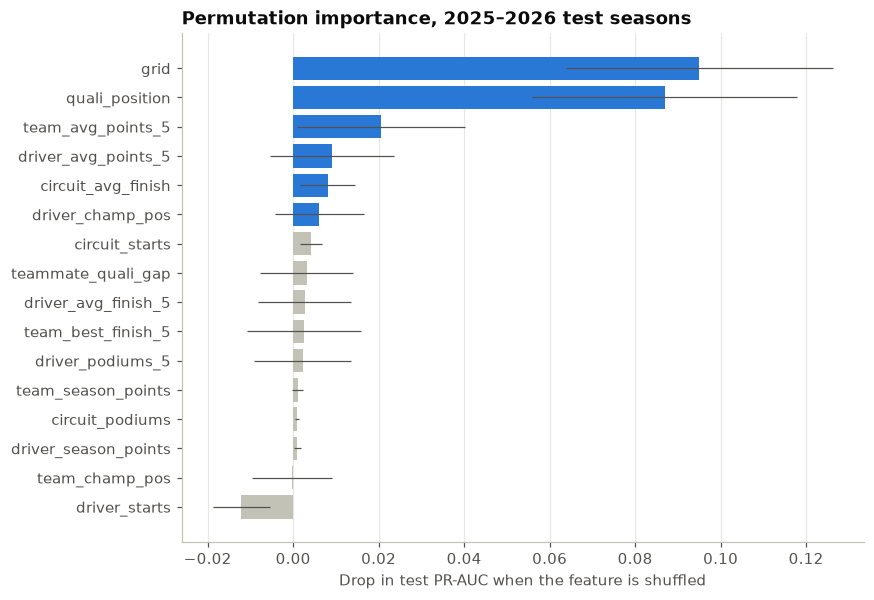

,feature,drop,std
0,grid,0.0950,0.0312
1,quali_position,0.0869,0.0310
6,team_avg_points_5,0.0206,0.0196
3,driver_avg_points_5,0.0090,0.0145
13,circuit_avg_finish,0.0081,0.0065
9,driver_champ_pos,0.0061,0.0104
12,circuit_starts,0.0041,0.0026
15,teammate_quali_gap,0.0031,0.0108
2,driver_avg_finish_5,0.0027,0.0109
7,team_best_finish_5,0.0026,0.0134


In [8]:
perm = permutation_importance(final, test[FEATURES], test.podium, scoring="average_precision",
                              n_repeats=20, random_state=SEED, n_jobs=-1)
importance = pd.DataFrame({"feature": FEATURES, "drop": perm.importances_mean, "std": perm.importances_std}) \
    .sort_values("drop")

fig, ax = plt.subplots(figsize=(8, 6))
colors = [ACCENT if d > 0.005 else MUTED for d in importance["drop"]]
ax.barh(importance.feature, importance["drop"], xerr=importance["std"], color=colors,
        error_kw={"ecolor": INK_2, "elinewidth": 0.8})
ax.set_xlabel("Drop in test PR-AUC when the feature is shuffled")
ax.grid(axis="y", visible=False)
ax.set_title("Permutation importance, 2025–2026 test seasons")
fig.savefig(FIGURES / "model_feature_importance.png")
plt.show()

importance.sort_values("drop", ascending=False).round(4)

## 5. Where the model beats the baseline

Podiums from outside the top 3 on the grid are the cases the baseline always misses.

In [9]:
outside = test[test.grid > 3]
print(f"Test podiums from outside the top 3: {outside.podium.sum()} of {test.podium.sum()}")
print(f"Caught by the forest: {(outside.podium & outside.pred).sum()}")
print(f"False alarms from outside the top 3: {((outside.podium == 0) & (outside.pred == 1)).sum()}")

test.loc[(test.grid > 3) & (test.podium == 1) & (test.pred == 1),
         ["year", "race_name", "code", "constructor", "grid", "prob", "positionOrder"]] \
    .sort_values("prob", ascending=False).head(10).round(2)

Test podiums from outside the top 3: 42 of 132
Caught by the forest: 27
False alarms from outside the top 3: 37


,year,race_name,code,constructor,grid,prob,positionOrder
3314,2026,Singapore Grand Prix,ANT,Mercedes,4.0,0.81,3.0
2623,2025,Emilia Romagna Grand Prix,NOR,McLaren,4.0,0.79,2.0
2907,2025,Las Vegas Grand Prix,RUS,Mercedes,4.0,0.79,2.0
3356,2026,Mexico City Grand Prix,VER,Red Bull,5.0,0.79,1.0
3009,2026,Japanese Grand Prix,LEC,Ferrari,4.0,0.77,3.0
2516,2025,Australian Grand Prix,RUS,Mercedes,4.0,0.77,3.0
3335,2026,United States Grand Prix,LEC,Ferrari,4.0,0.76,2.0
2604,2025,Miami Grand Prix,PIA,McLaren,4.0,0.74,1.0
3358,2026,Mexico City Grand Prix,ANT,Mercedes,4.0,0.74,3.0
3119,2026,Austrian Grand Prix,ANT,Mercedes,4.0,0.74,3.0


In [10]:
test[["raceId", "year", "round", "race_name", "driverId", "code", "constructor", "grid",
      "prob", "pred", "positionOrder", "podium"]].to_csv(PROCESSED / "test_predictions.csv", index=False)

## Key takeaways

1. **The forest beats the baseline on unseen seasons.** On 2025–2026 it reaches F1 0.722 (precision 0.609, recall 0.886) against 0.682 for "a top-3 start means a podium", with a PR-AUC of 0.731.
2. **It trades precision for recall.** The threshold chosen on 2023–2024 (0.57) makes the model predict more podiums than the baseline. It catches 117 of 132 podiums, compared with 90 for the baseline, and is right on 61% of its podium calls. More than half of the gain comes from this trade-off: a forest that only sees grid and qualifying already reaches F1 0.705.
3. **Form features add a modest, real gain.** Adding driver form, team form, standings and circuit history lifts F1 from 0.705 to 0.722 and PR-AUC from 0.714 to 0.731. The forest catches 27 of the 42 podiums from outside the top 3, at the cost of 37 false alarms from those positions.
4. **Grid and qualifying dominate.** Shuffling either one drops test PR-AUC by about 0.09. Team points over the last 5 races is next (0.02), followed by driver points, circuit history and championship position.
5. **The model holds up best when the rules change.** In 2026, with new regulations and two new teams, the baseline's F1 falls from 0.750 to 0.600, but the forest only falls from 0.751 to 0.689. Recent team form picks up the new pecking order (Mercedes, Antonelli) faster than grid position alone.
6. **`driver_starts` hurts on the test seasons.** Its importance is negative, probably because rookies like Antonelli scored podiums with few career starts, which didn't happen in the training years. It shouldn't be dropped based on test results alone, since that would tune the model on the test set; re-checking it on the validation seasons is the fair way to decide.
7. **Settings.** The best forest is shallow (`max_depth=4`, `min_samples_leaf=20`, `max_features="sqrt"`), which suggests the signal is simple and deeper trees overfit.